# Étude de cas 5 — Jalon 4 : L'histoire de la pompe (RNN, LSTM, GRU)
**Plan** : 0. Préparation · Q1 LSTM / GRU vs MLP (W ∈ {10, 30, 60}) · Q2 historiques courts (répétition vs zéros + masquage) · Q3 gradients (RNN simple vs LSTM, écrêtage) · Q4 (facultatif, non traitée) · Vérifications théoriques · Test · Page de décisions.

**Protocole** : réglages sur la **validation** (15 pompes, découpage par pompe) ; le **test** n'est utilisé qu'une fois, à la fin (`EVAL_TEST`).

## 0. Préparation

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import platform, os, sklearn
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
import keras
from tensorflow.keras import layers
from numpy.lib.stride_tricks import sliding_window_view

SEED = 42
RUL_MAX = 125
EVAL_TEST = True         # test exécuté une seule fois, à la fin du jalon
SEEDS = (0, 1)
EPOCHS, PATIENCE = 20, 4
tf.keras.utils.set_random_seed(SEED)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| tensorflow", tf.__version__, "| keras", keras.__version__, "| sklearn", sklearn.__version__)

A = np.load("data/uc5_flotteA.npz")
CAPTEURS = [f"c{i}" for i in range(8)]       # remplacer par les vrais noms si connus

JOURNAL = []
def log(essai, **res):
    # point d'appel unique : à adapter à `journaliser(jalon=4, ...)` du notebook de démarrage
    JOURNAL.append(dict(jalon=4, essai=essai, **res))

python 3.11.16 | numpy 2.4.6 | pandas 3.0.5 | tensorflow 2.21.0 | keras 3.15.1 | sklearn 1.9.1


**Données.** Capteurs normalisés **par régime de charge** (statistiques des cycles sains du train, RUL > 150), entrées = 8 capteurs + charge (**9 variables par cycle**), cible `min(RUL, 125)/125`, sortie sigmoïde.

In [2]:
def vers_df(s):
    d = pd.DataFrame(A["capteurs_" + s], columns=CAPTEURS)
    d["pompe"], d["cycle"], d["charge"] = A["pompe_" + s], A["cycle_" + s], A["charge_" + s]
    if "rul_" + s in A.files:
        d["rul"], d["mode"] = A["rul_" + s], A["mode_" + s]
    return d

TA = {s: vers_df(s) for s in ["train", "val", "test"]}
for s in TA:
    assert TA[s].sort_values(["pompe", "cycle"]).index.equals(TA[s].index)
sains = TA["train"][TA["train"].rul > 150]
mu_r, sd_r = sains.groupby("charge")[CAPTEURS].mean(), sains.groupby("charge")[CAPTEURS].std()

def normaliser(df):
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS].values - mu_r.loc[df.charge].values) / sd_r.loc[df.charge].values
    return out
NA = {s: normaliser(TA[s]) for s in TA}

def xy(df):
    X = df[CAPTEURS + ["charge"]].values.astype("float32")
    y = (np.minimum(df.rul.values, RUL_MAX) / RUL_MAX).astype("float32") if "rul" in df else None
    return X, y

def score_nasa(y, yhat):
    d = yhat - y
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

def metriques(yh, y):                      # yh, y en [0, 1] ; mesures en cycles
    yh, y = RUL_MAX * np.ravel(yh), RUL_MAX * np.ravel(y)
    return dict(rmse=float(np.sqrt(np.mean((yh - y) ** 2))),
                score30=float(30 * score_nasa(y, yh).mean()),
                anticipation=float((yh[y <= 30] < 30).mean()),
                fausses=float((yh[y > 60] < 30).mean()),
                biais=float((yh - y).mean()))

**Fenêtres (code de démarrage du jalon).** `sequences(df, W, remplissage)` donne une fenêtre de W cycles × 9 variables **par cycle observé** ; au début de l'historique, le 1ᵉʳ cycle est répété (`"repetition"`) ou remplacé par des zéros (`"zeros"`, à utiliser avec `layers.Masking`).

In [3]:
def sequences(df, W, remplissage="repetition"):
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[CAPTEURS + ["charge"]].values.astype("float32")
        if remplissage == "repetition":
            debut = np.repeat(v[:1], W - 1, axis=0)
        else:
            debut = np.zeros((W - 1, v.shape[1]), "float32")
        v = np.vstack([debut, v])
        X.append(sliding_window_view(v, W, axis=0).transpose(0, 2, 1))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "rul" in g:
            y.append(np.minimum(g.rul.values, RUL_MAX) / RUL_MAX)
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def normes_gradient(model, X, y):
    with tf.GradientTape() as tape:
        perte = keras.ops.mean((model(X, training=True)[:, 0] - y) ** 2)
    grads = tape.gradient(perte, model.trainable_variables)
    return {v.path: float(tf.norm(g)) for v, g in zip(model.trainable_variables, grads)}

_cache = {}
def SEQ(s, W, remplissage="repetition"):
    k = (s, W, remplissage)
    if k not in _cache:
        _cache[k] = sequences(NA[s], W, remplissage)
    return _cache[k]

## Q1. LSTM et GRU sur une fenêtre de W cycles, comparés au MLP de référence
**MLP de référence** (jalon 1) : dernier cycle seulement, 9 → 64 → 32 → 1, MSE. **Modèles récurrents** *many-to-one* : `LSTM(32)` ou `GRU(32)` → `Dense(1, sigmoïde)`, W ∈ {10, 30, 60}. Entraînement : Adam, arrêt anticipé sur la validation, 2 graines. Mesures en cycles sur la validation (tous les cycles) : `rmse`, `score30` (30 × score moyen, équivalent 30 pompes), `anticipation`, `fausses`, `biais` ; `taille_ko` = paramètres × 4 octets (cible de déploiement ≤ 2 Mo).

In [4]:
def construire_mlp():
    return keras.Sequential([layers.Input((9,)), layers.Dense(64, activation="relu"),
                             layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])

def construire_rnn(typ, W, masque=False, lr=1e-3, clipnorm=None, unites=32):
    couche = {"LSTM": layers.LSTM, "GRU": layers.GRU, "RNN": layers.SimpleRNN}[typ]
    L = [layers.Input((W, 9))] + ([layers.Masking(mask_value=0.0)] if masque else []) + \
        [couche(unites), layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(L)
    m.compile(keras.optimizers.Adam(lr, clipnorm=clipnorm) if clipnorm else keras.optimizers.Adam(lr), "mse")
    return m

def ajuster(m, Xt, yt, Xv, yv, seed, batch=256):
    tf.keras.utils.set_random_seed(seed)
    m.fit(Xt, yt, validation_data=(Xv, yv), epochs=EPOCHS, batch_size=batch, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)])
    return m

def entrainer_mlp(seed):
    tf.keras.utils.set_random_seed(seed)
    m = construire_mlp(); m.compile(keras.optimizers.Adam(1e-3), "mse")
    (Xt, yt), (Xv, yv) = xy(NA["train"]), xy(NA["val"])
    return ajuster(m, Xt, yt, Xv, yv, seed, batch=128), Xv, yv

def entrainer_rnn(typ, W, seed, remplissage="repetition", **kw):
    tf.keras.utils.set_random_seed(seed)
    m = construire_rnn(typ, W, masque=(remplissage == "zeros"), **kw)
    (Xt, yt, _), (Xv, yv, _) = SEQ("train", W, remplissage), SEQ("val", W, remplissage)
    return ajuster(m, Xt, yt, Xv, yv, seed), Xv, yv

In [5]:
rows = []
for seed in SEEDS:
    m, Xv, yv = entrainer_mlp(seed)
    r = metriques(m.predict(Xv, verbose=0), yv)
    rows.append(dict(modele="MLP (1 cycle)", W=1, seed=seed, **r, taille_ko=m.count_params() * 4 / 1024))
    log(f"mlp_seed{seed}", **{a: round(b, 3) for a, b in r.items()})
for typ in ("LSTM", "GRU"):
    for W in (10, 30, 60):
        for seed in SEEDS:
            m, Xv, yv = entrainer_rnn(typ, W, seed)
            r = metriques(m.predict(Xv, verbose=0), yv)
            rows.append(dict(modele=typ, W=W, seed=seed, **r, taille_ko=m.count_params() * 4 / 1024))
            log(f"{typ}_W{W}_seed{seed}", **{a: round(b, 3) for a, b in r.items()})
res1 = pd.DataFrame(rows)
tab1 = res1.groupby(["modele", "W"], sort=False)[["rmse", "score30", "anticipation", "fausses", "biais", "taille_ko"]].mean().round(3)
std1 = res1.groupby(["modele", "W"], sort=False)[["rmse", "score30"]].std().round(3).add_suffix("_std")
print(tab1.join(std1))

                    rmse  score30  anticipation  fausses  biais  taille_ko  \
modele        W                                                              
MLP (1 cycle) 1   18.950  759.447         0.800      0.0  1.076     10.754   
LSTM          10  17.819  578.251         0.763      0.0  1.961     21.129   
              30  17.958  623.862         0.747      0.0  1.924     21.129   
              60  17.975  652.117         0.742      0.0  2.725     21.129   
GRU           10  17.777  573.777         0.758      0.0  1.988     16.254   
              30  17.318  552.170         0.775      0.0  1.804     16.254   
              60  16.895  515.814         0.811      0.0  1.164     16.254   

                  rmse_std  score30_std  
modele        W                          
MLP (1 cycle) 1      0.052       18.683  
LSTM          10     0.114       20.735  
              30     0.224       42.971  
              60     0.459       37.807  
GRU           10     0.339       22.197  
   

In [6]:
rec = tab1.drop(index="MLP (1 cycle)")
TYPE_RETENU, W_RETENU = rec["score30"].idxmin()
print(f"retenu (score30 minimal) : {TYPE_RETENU}, W = {W_RETENU}")
print("MLP de référence : rmse =", tab1.loc[("MLP (1 cycle)", 1), "rmse"], "| score30 =", tab1.loc[("MLP (1 cycle)", 1), "score30"],
      "| anticipation =", tab1.loc[("MLP (1 cycle)", 1), "anticipation"])
print("cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10 | taille <= 2 Mo")

retenu (score30 minimal) : GRU, W = 60
MLP de référence : rmse = 18.95 | score30 = 759.447 | anticipation = 0.8
cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10 | taille <= 2 Mo


**Lecture.** Le **GRU à W = 60** est le meilleur : RMSE ≈ 16,9 et score ≈ 516, contre ≈ 18,95 et ≈ 759 pour le MLP (gain de ≈ 2 cycles en RMSE, très supérieur aux écarts-types entre graines (0,05 à 0,46 selon le modèle). Le GRU s'améliore quand W augmente (RMSE 17,8 → 17,3 → 16,9), alors que le LSTM reste autour de 17,8-18,0 et se dégrade en score (≈ 578 → 652) : à W égal, le GRU fait mieux ou autant. **L'anticipation reste le point faible** : ≈ 0,81 pour le GRU W = 60 (à peine au-dessus du MLP, 0,80), 0,74-0,76 pour le LSTM (en dessous du MLP), loin de la cible 0,90. Fausses alertes nulles partout (mesure peu discriminante). Taille ≈ 16-21 Ko, très en dessous de 2 Mo. *Limites* : 2 graines seulement ; l'écart LSTM / GRU à W = 10 et 30 est du même ordre que l'écart-type.

## Q2. Historiques plus courts que W : répétition vs zéros + masquage
Une pompe récente a moins de W cycles d'historique : les cycles « manquants » doivent être remplis. **Répétition** : on duplique le 1ᵉʳ cycle (fenêtre qui ressemble à une pompe stable). **Zéros + `Masking`** : les pas de temps remplis de zéros sont ignorés par le réseau. On entraîne le modèle retenu avec chaque remplissage, puis on mesure sur les cycles de validation dont l'historique est **plus court que W** (pompes récentes) et sur tous les cycles.

In [7]:
pos = NA["val"].groupby("pompe").cumcount().values
court = pos < (W_RETENU - 1)                     # historique observé < W cycles
print(f"cycles de validation à historique court (< {W_RETENU} cycles) : {court.sum()} sur {len(court)}")

rows = []
for remp in ("repetition", "zeros"):
    for seed in SEEDS:
        m, Xv, yv = entrainer_rnn(TYPE_RETENU, W_RETENU, seed, remp)
        yh = m.predict(Xv, verbose=0)
        rc, ra = metriques(yh[court], yv[court]), metriques(yh, yv)
        rows.append(dict(remplissage=remp + (" + masquage" if remp == "zeros" else ""), seed=seed,
                         rmse_court=rc["rmse"], biais_court=rc["biais"], fausses_court=rc["fausses"],
                         rmse_tout=ra["rmse"], score30_tout=ra["score30"]))
        log(f"q2_{remp}_seed{seed}", rmse_court=round(rc["rmse"], 3), rmse_tout=round(ra["rmse"], 3))
res2 = pd.DataFrame(rows)
tab2 = res2.groupby("remplissage", sort=False).agg(["mean", "std"]).drop(columns="seed").round(3)
print(tab2)
PAD_RETENU = "zeros" if tab2.loc["zeros + masquage", ("rmse_court", "mean")] < tab2.loc["repetition", ("rmse_court", "mean")] else "repetition"
print("remplissage retenu (RMSE minimal sur les historiques courts) :", PAD_RETENU)

cycles de validation à historique court (< 60 cycles) : 885 sur 4170


C:\Users\amine\AppData\Local\Temp\ipykernel_17772\4107837583.py:33: RuntimeWarning: Mean of empty slice
  anticipation=float((yh[y <= 30] < 30).mean()),
c:\Users\amine\.conda\envs\ai-env\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\amine\AppData\Local\Temp\ipykernel_17772\4107837583.py:33: RuntimeWarning: Mean of empty slice
  anticipation=float((yh[y <= 30] < 30).mean()),
c:\Users\amine\.conda\envs\ai-env\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


                 rmse_court        biais_court        fausses_court       \
                       mean    std        mean    std          mean  std   
remplissage                                                                
repetition            9.166  1.284      -7.137  1.096           0.0  0.0   
zeros + masquage      8.702  0.699      -5.595  1.036           0.0  0.0   

                 rmse_tout        score30_tout          
                      mean    std         mean     std  
remplissage                                             
repetition          16.895  0.124      515.814  48.930  
zeros + masquage    17.159  0.322      529.526  14.288  
remplissage retenu (RMSE minimal sur les historiques courts) : zeros


**Lecture.** Sur les cycles à historique court (pompes récentes, 885 cycles), les deux remplissages **sous-estiment** légèrement la RUL (biais ≈ −7 pour la répétition, ≈ −5,6 pour zéros + masquage) sans produire de fausses alertes. Le masquage fait un peu mieux sur ces cycles (RMSE ≈ 8,7 contre ≈ 9,2) mais l'écart (≈ 0,5) est **inférieur aux écarts-types entre graines (0,7 à 1,3)** : il n'est pas démontré. Sur l'ensemble de la validation, la répétition est légèrement meilleure (RMSE ≈ 16,9 contre ≈ 17,2). La règle du notebook (RMSE minimal sur historiques courts) retient zéros + masquage, mais les deux options sont statistiquement équivalentes ici.

## Q3. Normes des gradients : RNN simple vs LSTM sur fenêtres longues (W = 60)
Deux observations : (a) la **norme du gradient** (globale et du noyau récurrent) au cours de l'entraînement, mesurée sur un lot fixe toutes les 25 itérations (fonction `normes_gradient` du code de démarrage) ; (b) la **norme du gradient de la perte par rapport à l'entrée de chaque pas de temps**, à l'initialisation : si elle décroît vers les pas anciens, le gradient « disparaît » à travers le temps. **Écrêtage** : `clipnorm = 0,05`, seuil choisi d'après les normes observées (gradient typique ≈ 0,01 à 0,4 ; un seuil de 1 ne se déclencherait jamais). Taux d'apprentissage élevé (5·10⁻³) pour provoquer l'instabilité ; `part_ecretee` = part des mesures où la norme globale dépasse 0,05.

In [8]:
W3 = 60
Xt3, yt3, _ = SEQ("train", W3); Xv3, yv3, _ = SEQ("val", W3)
rng = np.random.default_rng(0); lot = rng.choice(len(Xt3), 512, replace=False)
Xlot, ylot = Xt3[lot], yt3[lot]

class SuiviGradient(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.glob, self.rec, self.it = [], [], 0
    def on_train_batch_end(self, batch, logs=None):
        self.it += 1
        if self.it % 25 == 1:
            g = normes_gradient(self.model, Xlot, ylot)
            self.glob.append(np.sqrt(sum(v ** 2 for v in g.values())))
            self.rec.append(next(v for k, v in g.items() if "recurrent" in k))

def grad_par_pas(m):
    X = tf.convert_to_tensor(Xlot)
    y = tf.convert_to_tensor(ylot)
    with tf.GradientTape() as t:
        t.watch(X); perte = tf.reduce_mean((m(X, training=False)[:, 0] - y) ** 2)
    return tf.norm(t.gradient(perte, X), axis=2).numpy().mean(0)       # (W,)

CONFIGS = [("RNN simple", "RNN", None), ("RNN simple + écrêtage", "RNN", 0.05),
           ("LSTM", "LSTM", None), ("LSTM + écrêtage", "LSTM", 0.05)]
suivi, profils, rows = {}, {}, []
for nom, typ, clip in CONFIGS:
    tf.keras.utils.set_random_seed(SEED)
    m = construire_rnn(typ, W3, lr=5e-3, clipnorm=clip)
    if clip is None: profils[nom] = grad_par_pas(m)             # profil à l'initialisation
    cb = SuiviGradient()
    h = m.fit(Xt3, yt3, validation_data=(Xv3, yv3), epochs=8, batch_size=256, verbose=0, callbacks=[cb])
    suivi[nom] = cb
    r = metriques(m.predict(Xv3, verbose=0), yv3)
    rows.append(dict(config=nom, rmse_val=r["rmse"], grad_max=max(cb.glob), grad_median=float(np.median(cb.glob)), part_ecretee=float(np.mean(np.array(cb.glob) > 0.05)),
                     loss_nan=bool(np.isnan(h.history["loss"]).any())))
    log(f"q3_{nom}", rmse_val=round(r["rmse"], 2), grad_max=round(max(cb.glob), 3))
tab3 = pd.DataFrame(rows).round(3); print(tab3.to_string(index=False))

               config  rmse_val  grad_max  grad_median  part_ecretee  loss_nan
           RNN simple    18.158     0.389        0.016          0.04     False
RNN simple + écrêtage    18.463     0.389        0.017          0.04     False
                 LSTM    23.313     0.265        0.020          0.12     False
      LSTM + écrêtage    22.442     0.265        0.026          0.28     False


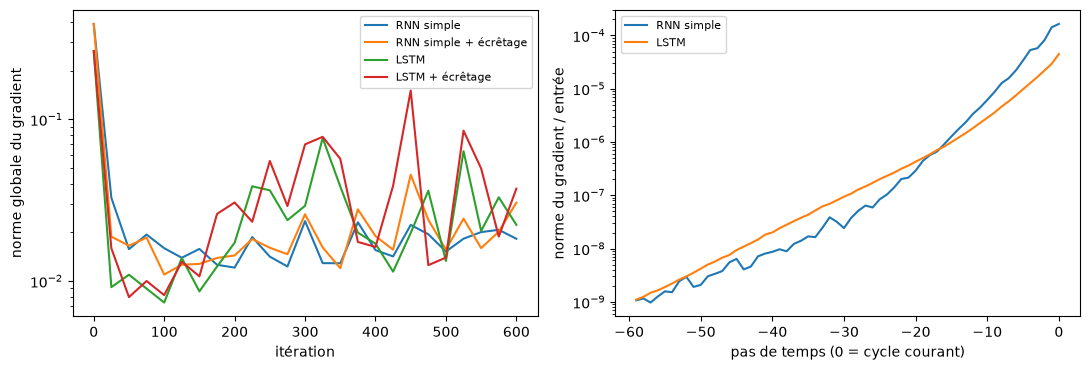

rapport gradient (cycle le plus ancien / cycle courant) : {'RNN simple': 6.5e-06, 'LSTM': 2.4e-05}


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nom, cb in suivi.items():
    ax[0].semilogy(np.arange(len(cb.glob)) * 25, cb.glob, label=nom)
ax[0].set_xlabel("itération"); ax[0].set_ylabel("norme globale du gradient"); ax[0].legend(fontsize=8)
for nom, p in profils.items():
    ax[1].semilogy(np.arange(-W3 + 1, 1), p, label=nom)
ax[1].set_xlabel("pas de temps (0 = cycle courant)"); ax[1].set_ylabel("norme du gradient / entrée"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
rapport = {n: p[0] / p[-1] for n, p in profils.items()}
print("rapport gradient (cycle le plus ancien / cycle courant) :", {n: float(f"{v:.2g}") for n, v in rapport.items()})

**Lecture.** *Disparition* : à l'initialisation, la norme du gradient par rapport à l'entrée chute d'environ **5 ordres de grandeur** entre le cycle courant et le cycle le plus ancien de la fenêtre (rapport ≈ 6,5·10⁻⁶ pour le RNN simple, ≈ 2,4·10⁻⁵ pour le LSTM) : sur 60 pas, les deux réseaux « n'entendent » presque plus les cycles anciens au départ ; le LSTM n'est meilleur que d'un facteur ≈ 4 par cette mesure (une seule graine, à l'initialisation seulement). *Explosion* : aucune explosion franche n'a été observée (norme globale maximale ≈ 0,4, sans NaN). Avec un seuil d'écrêtage de 0,05, l'écrêtage se déclenche dans 4 à 28 % des mesures : il **améliore le LSTM** (23,3 → 22,4) mais **dégrade légèrement le RNN simple** (18,2 → 18,5). À ce taux d'apprentissage élevé (5·10⁻³) le LSTM est instable (RMSE ≈ 23,3, pire que le MLP) : l'écrêtage atténue le problème sans le supprimer. *Limites* : une graine, 8 époques ; les écarts avec/sans écrêtage (0,6 et 1,6 cycle) n'ont pas été testés contre la variabilité entre graines.

## Q4 (facultatif) — CNN par spectrogramme + LSTM sur la suite des cycles
**Non traitée** dans ce notebook : elle est facultative et le temps de calcul disponible a été consacré aux questions 1 à 3 et aux vérifications théoriques.

## Vérifications théoriques (à la main, puis vérifiées par le code)

**1. Paramètres d'un LSTM à 32 unités, 9 variables par cycle.** 4 portes (entrée, oubli, cellule, sortie), chacune avec un noyau d'entrée (9 × 32), un noyau récurrent (32 × 32) et un biais (32) :
4 × (9·32 + 32·32 + 32) = 4 × 1 344 = **5 376** (Keras : noyau 9×128 = 1 152, récurrent 32×128 = 4 096, biais 128).
**GRU** (Keras, `reset_after=True`) : 3 portes (réinitialisation, mise à jour, candidat) et **deux** vecteurs de biais : 3 × (9·32 + 32·32) + 2 × 96 = 3 × 1 312 + 192 = **4 128** (noyau 9×96 = 864, récurrent 32×96 = 3 072, biais 2×96 = 192). Avec la tête `Dense(32 → 1)` : +33.

**2. Nombre de fenêtres d'une pompe de 275 cycles, W = 30.** Fenêtres **complètes** (pas de 1) : 275 − 30 + 1 = **246**. Avec le remplissage du code de démarrage (1 fenêtre par cycle observé) : **275**, dont W − 1 = 29 fenêtres partiellement remplies.

In [14]:
for nom, couche in (("LSTM", layers.LSTM), ("GRU", layers.GRU)):
    m = keras.Sequential([layers.Input((30, 9)), couche(32)])
    print(f"{nom}(32), 9 variables : {m.count_params()} paramètres | poids :", [tuple(w.shape) for w in m.weights])
assert keras.Sequential([layers.Input((30, 9)), layers.LSTM(32)]).count_params() == 4 * (9 * 32 + 32 * 32 + 32) == 5376
assert keras.Sequential([layers.Input((30, 9)), layers.GRU(32)]).count_params() == 3 * (9 * 32 + 32 * 32) + 2 * 96 == 4128

faux = pd.DataFrame(np.zeros((275, 9), "float32"), columns=CAPTEURS + ["charge"])
faux["pompe"], faux["cycle"] = 1, np.arange(275)
print("fenêtres (code de démarrage, W=30) :", sequences(faux, 30)[0].shape[0], "| fenêtres complètes :", 275 - 30 + 1)

LSTM(32), 9 variables : 5376 paramètres | poids : [(9, 128), (32, 128), (128,)]
GRU(32), 9 variables : 4128 paramètres | poids : [(9, 96), (32, 96), (2, 96)]
fenêtres (code de démarrage, W=30) : 275 | fenêtres complètes : 246


## Test (à exécuter UNE seule fois, à la fin)
`EVAL_TEST` vaut déjà `True` dans la première cellule ; le test a été exécuté **une seule fois**, à la fin. Pour le réexécuter, relancer uniquement cette cellule. Le modèle retenu (type, W, remplissage) est réentraîné avec la graine fixée ; mesures **par pompe**, au dernier cycle observé (30 pompes) ; taille = fichier `.keras` sans optimiseur.

In [13]:
if EVAL_TEST:
    final, Xv_f, yv_f = entrainer_rnn(TYPE_RETENU, W_RETENU, SEED, PAD_RETENU)
    print("validation :", {a: round(b, 3) for a, b in metriques(final.predict(Xv_f, verbose=0), yv_f).items()})
    Xt, _, dern = sequences(NA["test"], W_RETENU, PAD_RETENU)
    pompes = TA["test"].sort_values(["pompe", "cycle"]).pompe.values[dern]
    rul_fin = pd.Series(A["rul_fin_test"], index=A["pompe_id_test"]).loc[pompes].values
    yh, y = RUL_MAX * final.predict(Xt[dern], verbose=0).ravel(), np.minimum(rul_fin, RUL_MAX)
    print("TEST | RMSE :", round(float(np.sqrt(np.mean((yh - y) ** 2))), 2),
          "| score :", round(float(score_nasa(y, yh).sum()), 0),
          "| anticipation :", round(float((yh[rul_fin <= 30] < 30).mean()), 3),
          "| fausses alertes :", round(float((yh[rul_fin > 60] < 30).mean()), 3))
    try: final.save("modele_j4.keras", include_optimizer=False)
    except TypeError: final.save("modele_j4.keras")
    print("taille du modèle :", round(os.path.getsize("modele_j4.keras") / 1024, 1), "Ko (cible <= 2 Mo)")
else:
    print("Test non évalué (EVAL_TEST = False).")

validation : {'rmse': 16.954, 'score30': 530.124, 'anticipation': 0.772, 'fausses': 0.0, 'biais': 0.856}
TEST | RMSE : 23.79 | score : 1452.0 | anticipation : 0.818 | fausses alertes : 0.0
taille du modèle : 74.5 Ko (cible <= 2 Mo)


## Page de décisions

**Tableau des résultats (validation, 2 graines)** : détail dans `tab1` (Q1), `tab2` (Q2), `tab3` (Q3) ; journal dans `journal_jalon4.csv`.

| Modèle (W) | RMSE | Score (30 pompes) | Anticipation | Fausses alertes | Taille |
|---|---|---|---|---|---|
| MLP, 1 cycle (référence) | 18,95 | 759 | 0,80 | 0,00 | 10,8 Ko |
| LSTM, W = 10 / 30 / 60 | 17,8 / 18,0 / 18,0 | 578 / 624 / 652 | 0,76 / 0,75 / 0,74 | 0,00 | 21 Ko |
| GRU, W = 10 / 30 / 60 | 17,8 / 17,3 / **16,9** | 574 / 552 / **516** | 0,76 / 0,78 / **0,81** | 0,00 | 16 Ko |

*Lecture du tableau* : les valeurs GRU W = 60 sont celles de `tab1` (remplissage par répétition) ; le modèle final déployé utilise zéros + masquage, et ses mesures propres figurent dans l'écart aux cibles (validation : RMSE 16,95, anticipation 0,772 ; test : RMSE 23,79, anticipation 0,818).

**Longueur de fenêtre retenue : GRU, W = 60.** Meilleur RMSE et meilleur score ; avec répétition, c'est le seul modèle dont l'anticipation dépasse celle du MLP (0,811 contre 0,800), mais avec le remplissage final (zéros + masquage) elle retombe à 0,772 (voir l'écart aux cibles). Le GRU s'améliore de façon régulière avec W alors que le LSTM ne profite pas des fenêtres longues. Coûts : calcul plus long (≈ 6,6 s/époque contre ≈ 2,5 s à W = 10 sur notre machine), 59 cycles de remplissage en début d'historique (voir ci-dessous), et un modèle qui reste minuscule (≈ 16 Ko).

**Traitement des historiques courts : zéros + `Masking`, en convention.** Le masquage signale explicitement les données absentes au lieu d'inventer un historique stable ; sur les 885 cycles à historique court il donne un RMSE légèrement plus bas (≈ 8,7 contre ≈ 9,2) et un biais plus faible, **mais l'écart n'est pas démontré** (inférieur aux écarts-types) et la répétition est un peu meilleure sur l'ensemble. Aucune fausse alerte dans les deux cas. Les zéros se confondent avec la valeur moyenne normalisée : on s'appuie donc sur `Masking`, jamais sur les zéros seuls.

**Réponses aux vérifications théoriques.** (1) LSTM(32), 9 variables : 4 × (9·32 + 32·32 + 32) = **5 376** paramètres ; GRU(32) Keras (`reset_after=True`) : 3 × (9·32 + 32·32) + 2·96 = **4 128** (+ 33 pour la tête `Dense`). (2) Pompe de 275 cycles, W = 30 : **246** fenêtres complètes (275 − 30 + 1) ; **275** avec le remplissage du code de démarrage (dont 29 partiellement remplies).

**Gradients.** Disparition nette sur 60 pas pour le RNN simple et le LSTM à l'initialisation (rapport ≈ 10⁻⁵ entre cycle ancien et cycle courant) ; pas d'explosion franche ; l'écrêtage (seuil 0,05) améliore le LSTM (23,3 → 22,4) mais dégrade légèrement le RNN simple (18,2 → 18,5) ; il ne rend pas le LSTM stable. *Conclusion de conception* : préférer un GRU/LSTM à taux d'apprentissage modéré, avec écrêtage en garde-fou.

**Écart aux cibles (cibles = système final sur le test, par pompe).** Sur la **validation** (modèle final retenu, zéros + masquage, tous les cycles) : RMSE 16,95 (≤ 23 ✓), score pour 30 pompes 530 (≤ 1 200 ✓), fausses alertes 0,00 (≤ 0,10 ✓), taille 74,5 Ko (≤ 2 Mo ✓), mais **anticipation 0,772 (≥ 0,90 ✗)** — et non 0,81, qui est la moyenne du GRU W = 60 avec répétition dans `tab1`. Sur le **test** (30 pompes, dernier cycle) : RMSE 23,79 (≤ 23 ✗, écart +0,79), score 1 452 (≤ 1 200 ✗), anticipation 0,818 (≥ 0,90 ✗), fausses alertes 0,00 (≤ 0,10 ✓), taille 74,5 Ko (≤ 2 Mo ✓). L'écart est donc confirmé sur le test : la RMSE et le score dépassent les cibles, l'anticipation reste en dessous. Causes plausibles : entre 30 et 60 cycles de la panne le défaut est peu visible dans les capteurs agrégés ; les spectrogrammes ne sont pas utilisés ici (Q4 non traitée) ; le RMSE moyen est dominé par la zone saine plafonnée. *Limites* : données simulées ; 2 graines ; 15 pompes de validation ; anticipation et fausses alertes mesurées par cycle (et non par pompe) en validation ; une seule graine pour l'étude des gradients ; Q4 facultative non traitée.

In [12]:
pd.DataFrame(JOURNAL).to_csv("journal_jalon4.csv", index=False)
print(len(JOURNAL), "essais journalisés -> journal_jalon4.csv")

22 essais journalisés -> journal_jalon4.csv
